# Oficina  modelo associativo e interpretacao substantiva

[ Abrir este notebook no Google Colab](https://colab.research.google.com/github/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_07/05_oficina_modelo_associativo.ipynb)

**Produto:** uma nova secao no mesmo relatorio-notebook cumulativo. Nao entregue
um arquivo separado. Use seu problema, corpus e decisoes das unidades anteriores.

![A pergunta leva a especificacao, diagnostico, casos e afirmacao limitada.](imagens/05_cadeia_argumento.svg)

## 1. Antes de modelar: decisao de pertinencia

A regressao so e adequada quando ha uma resposta definida, variacao suficiente,
unidades comparaveis e numero razoavel de casos. Se seu corpus nao atende a essas
condicoes, a entrega correta e uma **nao adocao fundamentada**, acompanhada por
uma analise descritiva coerente. Nao fabrique observacoes nem troque o problema
apenas para usar a tecnica.

## 2. O que acrescentar ao relatorio-notebook

Inclua uma secao `Unidade 7  Modelo de associacao condicionada` com:

1. pergunta e justificativa do modelo ou da nao adocao;
2. unidade de analise, resposta, explicativas, escalas e ausencias;
3. formula conceitual antes do codigo;
4. tabela ou grafico de resultados com legenda autonoma;
5. ao menos um diagnostico e inspecao de casos;
6. interpretacao substantiva em escala compreensivel;
7. limites, alternativas e linguagem causal compativel com o desenho.

O codigo deve aparecer junto da transformacao ou analise que realiza. Nao use um
`DataFrame` para substituir argumentos que devem ser escritos em prosa.

## Unidade 7 - Modelo de associacao condicionada

**Pergunta e justificativa:** quais caracteristicas dos discursos do corpus estao associadas a `ocorrencias_liberdade` O modelo linear foi adotado como resumo exploratorio porque ha uma resposta numerica, 12 discursos comparaveis e variacao observada. A estimacao nao substitui a leitura dos trechos nem permite afirmar causalidade.

**Unidade de analise:** cada discurso identificado por `id_doc`. **Resposta:** `ocorrencias_liberdade`, contagem de ocorrencias observadas. **Explicativas:** `palavras`, `ano` e `ttr`, todas numericas. As escalas sao, respectivamente, quantidade de palavras, ano do discurso e proporcao de tipos sobre tokens. `partido` esta ausente em todo o arquivo e por isso nao foi usado. Os zeros de ocorrencias sao ausencias observadas, nao dados faltantes.

**Formula conceitual:** `ocorrencias_liberdade_i = beta0 + beta1 palavras_i + beta2 ano_i + beta3 ttr_i + erro_i`. Cada coeficiente e uma associacao condicionada as demais explicativas. A formula vem antes do codigo para separar a especificacao do resultado.

A celula seguinte carrega o arquivo derivado real e mostra a especificacao. As celulas seguintes estimam a formula, apresentam a tabela e o grafico, e inspecionam o caso com maior residuo.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

possiveis = [Path.cwd() / "dados", Path.cwd().parents[1] / "dados", Path.cwd().parents[2] / "dados"]
PASTA_DADOS = next(p for p in possiveis if (p / "derivados" / "documentos_processaveis.csv").exists())
dados_projeto = pd.read_csv(PASTA_DADOS / "derivados" / "documentos_processaveis.csv").sort_values("ano").reset_index(drop=True)
variaveis = ["palavras", "ano", "ttr"]
print("Unidades de analise:", len(dados_projeto))
print("Variaveis:", variaveis + ["ocorrencias_liberdade"])
print("partido ausente:", dados_projeto["partido"].isna().all())


Unidades de analise: 12
Variaveis: ['palavras', 'ano', 'ttr', 'ocorrencias_liberdade']
partido ausente: True


In [2]:
X = np.column_stack([np.ones(len(dados_projeto)), dados_projeto[variaveis].to_numpy(dtype=float)])
y = dados_projeto["ocorrencias_liberdade"].to_numpy(dtype=float)
beta = np.linalg.lstsq(X, y, rcond=None)[0]
previstos = X @ beta
residuos = y - previstos
r2 = 1 - np.sum(residuos ** 2) / np.sum((y - y.mean()) ** 2)
resultado_modelo = pd.DataFrame({"termo": ["intercepto", *variaveis], "coeficiente": beta})
display(resultado_modelo.round(4))
print(f"R2={r2:.3f} | RMSE={np.sqrt(np.mean(residuos ** 2)):.3f}")


,termo,coeficiente
0,intercepto,484.5324
1,palavras,-0.0006
2,ano,-0.2308
3,ttr,-39.4448


R2=0.289 | RMSE=4.480


,id_doc,ano,presidente,ocorrencias_liberdade,previsto,residuo
0,DISCURSO_1985_SARNEY,1985,José Sarney,19,9.345,9.655
1,DISCURSO_1990_COLLOR,1990,Fernando Collor de Mello,9,8.287,0.713
2,DISCURSO_1992_ITAMAR,1992,Itamar Franco,0,3.607,-3.607
3,DISCURSO_1995_FHC,1995,Fernando Henrique Cardoso,8,7.115,0.885
4,DISCURSO_1999_FHC,1999,Fernando Henrique Cardoso,1,5.627,-4.627
5,DISCURSO_2003_LULA,2003,Luiz Inácio Lula da Silva,0,5.154,-5.154
6,DISCURSO_2007_LULA,2007,Luiz Inácio Lula da Silva,0,4.706,-4.706
7,DISCURSO_2011_DILMA,2011,Dilma Rousseff,4,4.808,-0.808
8,DISCURSO_2015_DILMA,2015,Dilma Rousseff,3,4.030,-1.030
9,DISCURSO_2016_TEMER,2016,Michel Temer,1,2.906,-1.906


Caso com maior residuo: {'id_doc': 'DISCURSO_1985_SARNEY', 'ano': 1985}


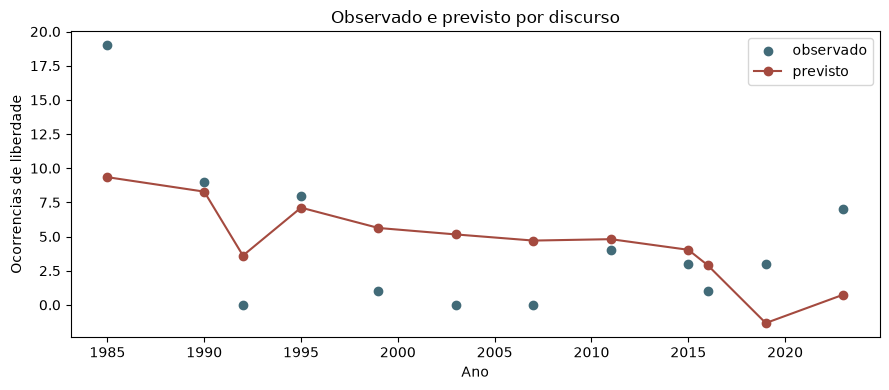

In [3]:
diagnostico = dados_projeto[["id_doc", "ano", "presidente", "ocorrencias_liberdade"]].copy()
diagnostico["previsto"] = previstos
diagnostico["residuo"] = residuos
display(diagnostico.round(3))
indice = np.argmax(np.abs(residuos))
print("Caso com maior residuo:", diagnostico.iloc[indice][["id_doc", "ano"]].to_dict())
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(dados_projeto["ano"], y, label="observado", color="#426b78")
ax.plot(dados_projeto["ano"], previstos, label="previsto", color="#a44a3f", marker="o")
ax.set(xlabel="Ano", ylabel="Ocorrencias de liberdade", title="Observado e previsto por discurso")
ax.legend(); plt.tight_layout(); plt.show()


### Resultado e interpretacao

A tabela e o grafico apresentam os valores observados, os valores previstos e os residuos por discurso. O ajuste obtido foi R2=0,289 e RMSE=4,480. Essas metricas descrevem o ajuste dentro deste corpus; nao sao evidencias de previsao fora da amostra. O maior residuo foi localizado em `DISCURSO_1985_SARNEY` e deve ser retomado nos trechos e coocorrencias ja produzidos nas unidades anteriores.

A escala substantiva e a contagem de ocorrencias de liberdade por discurso. Um coeficiente indica a diferenca prevista associada a uma variacao da explicativa, mantendo as demais constantes; ele nao significa que a explicativa produza o vocabulario. Como o corpus e pequeno, historico e observacional, ano, extensao, TTR e escolhas retoricas podem estar associados a conjunturas nao medidas.

As alternativas sao manter a analise descritiva caso a pertinencia seja rejeitada, comparar taxas normalizadas pela extensao e retornar aos trechos para interpretar os casos. O desenho nao sustenta linguagem causal: o resultado deve ser descrito como associacao exploratoria condicionada, com limites de medicao, selecao do corpus e generalizacao.


## 3. Roteiro de trabalho em 70 minutos

| Tempo | Acao | Evidencia no notebook |
|---:|---|---|
| 010 | recuperar pergunta e corpus | paragrafo de pertinencia |
| 1020 | definir resposta e explicativas | quadro de especificacao |
| 2040 | estimar ou justificar nao adocao | codigo reproduzivel ou diagnostico |
| 4052 | produzir figura/tabela e voltar aos casos | saida comentada |
| 5262 | redigir interpretacao e limites | paragrafo substantivo |
| 6270 | revisao por pares | registro de uma mudanca |

### U07-A06  Oficina  incremento do relatorio-notebook

**Dinamica:** trabalhe em seu proprio projeto seguindo o roteiro. A pessoa docente
faz duas paradas coletivas: aos 20 minutos para conferir especificacoes e aos 52
para conferir diagnosticos. Entregue o mesmo notebook ja usado nas outras unidades.

**Resposta:** A nova secao foi incorporada ao mesmo relatorio-notebook e aplica o roteiro ao projeto cumulativo. Ela apresenta a pergunta, a justificativa do modelo, a unidade `id_doc`, a resposta `ocorrencias_liberdade`, as explicativas `palavras`, `ano` e `ttr`, suas escalas, a ausencia de `partido`, a formula antes do codigo, a tabela, o grafico, o diagnostico e a inspecao do caso `DISCURSO_1985_SARNEY`. Nao foi criado arquivo de dados separado.

### U07-A07  Revisao por pares  afirmacao, evidencia e limite

**Dinamica (20 minutos):** o colega localiza, sem explicacao oral, (a) a pergunta,
(b) a unidade de analise, (c) a interpretacao de um resultado, (d) um caso
inspecionado e (e) o limite causal. Registra um ponto claro, uma duvida e uma
mudanca prioritaria. O autor implementa ou justifica por que nao implementou.

**Resposta:** O ponto claro foi a localizacao da pergunta, da unidade `id_doc`, da tabela, do caso inspecionado e do limite causal. A duvida foi se um coeficiente poderia ser interpretado como mudanca historica ou como causa do uso de liberdade. A mudanca prioritaria foi explicitar a formula antes do codigo, registrar as ausencias, preservar os zeros observados e ligar o maior residuo aos trechos e coocorrencias das unidades anteriores. A decisao foi manter a interpretacao como associacao exploratoria condicionada, sem afirmacao causal.

## 4. Criterios de avaliacao

- coerencia entre pergunta, resposta, explicativas e modelo;
- execucao reproduzivel e dados documentados;
- interpretacao de escala, referencia e condicionamento;
- diagnostico ligado a casos, nao apenas a metricas;
- distincao explicita entre associacao e causalidade;
- integracao com o argumento cumulativo do projeto.

## Fechamento

O modelo e uma compressao argumentativa: torna comparacoes explicitas, mas nao
substitui critica das fontes, contexto e desenho de pesquisa. Mesmo com bom ajuste,
o modelo nao demonstra causalidade. A Unidade 8 retomara
essa base ao separar explicacao e previsao e avaliar desempenho fora da amostra.